# Remaining Useful Life (RUL) Target Label Generation
### B.Tech Mini Project: Aircraft Engine Predictive Maintenance (NASA C-MAPSS FD001)

This notebook establishes the ground-truth **Remaining Useful Life (RUL)** target labels for training predictive maintenance models on the NASA C-MAPSS FD001 dataset.

#### Workflow Stages:
1. **Stage 1 - Load & Inspect Data:** Ingest FD001 files, verify shapes/fleet counts, and document structural differences between training and test sets.
2. **Stage 2 - Generate Training RUL Labels:** Compute linear `raw_RUL` from observed maximum cycle, apply piecewise constant-linear clipping ($RUL_{max} = 125$), and store in `RUL`.
3. **Stage 3 - Validate Labels:** Perform rigorous boundary validations (non-negativity, terminal cycle zero condition, upper threshold saturation, and descriptive statistics).

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Visual formatting configuration for academic report figures
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

print("NumPy version :", np.__version__)
print("Pandas version:", pd.__version__)

NumPy version : 2.5.4
Pandas version: 3.1.0


---
## Stage 1: Load and Inspect Data

We reuse the standardized 26-column naming schema from `02_data_inspection.ipynb`:
- **Identifiers:** `unit` (engine ID), `cycle` (operational flight cycle)
- **Operational Settings:** `op_setting_1`, `op_setting_2`, `op_setting_3`
- **Telemetry Channels:** 21 sensor measurements (`sensor_1` through `sensor_21`)

In [2]:
# Standardized column schema
columns = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# Robust data directory resolution (supports running from repo root or notebooks/)
DATA_DIR = Path("../data/raw/CMaps") if Path("../data/raw/CMaps").exists() else Path("data/raw/CMaps")

# Ingest raw C-MAPSS dataset files
train_df = pd.read_csv(DATA_DIR / "train_FD001.txt", sep=r"\s+", header=None, names=columns)
test_df = pd.read_csv(DATA_DIR / "test_FD001.txt", sep=r"\s+", header=None, names=columns)
rul_df = pd.read_csv(DATA_DIR / "RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])

print("=" * 65)
print("DATASET INGESTION & SHAPE VERIFICATION")
print("=" * 65)
print(f"Training Data (train_df) : {train_df.shape}  ({train_df.shape[0]:,} rows, {train_df.shape[1]} columns)")
print(f"Test Data (test_df)      : {test_df.shape}  ({test_df.shape[0]:,} rows, {test_df.shape[1]} columns)")
print(f"Ground Truth RUL (rul_df): {rul_df.shape}    ({rul_df.shape[0]:,} ground truth test RUL records)")
print("-" * 65)
print(f"Unique Training Engines  : {train_df['unit'].nunique()}")
print(f"Unique Test Engines      : {test_df['unit'].nunique()}")
print("=" * 65)

DATASET INGESTION & SHAPE VERIFICATION
Training Data (train_df) : (20631, 26)  (20,631 rows, 26 columns)
Test Data (test_df)      : (13096, 26)  (13,096 rows, 26 columns)
Ground Truth RUL (rul_df): (100, 1)    (100 ground truth test RUL records)
-----------------------------------------------------------------
Unique Training Engines  : 100
Unique Test Engines      : 100


### Training Data vs. Test Data Operational Differences

| Aspect | Training Set (`train_df`) | Test Set (`test_df`) |
| :--- | :--- | :--- |
| **Trajectory Horizon** | **Run-to-failure**: Each engine is continuously monitored from baseline operation until system failure. | **Truncated time-series**: Telemetry collection is stopped at an unspecified cycle prior to system failure. |
| **Terminal Health State** | The final observed cycle marks catastrophic system failure ($RUL = 0$). | The final observed cycle represents a functional engine with positive remaining life. |
| **RUL Ground Truth Source** | Computed directly from telemetry by subtracting current cycle from each unit's maximum operating cycle. | Provided independently in `RUL_FD001.txt` as a single ground-truth scalar for the last recorded cycle of each test unit. |
| **Record Count** | 20,631 total cycles across 100 engines (mean: ~206 cycles per engine). | 13,096 total cycles across 100 engines (mean: ~131 cycles per engine). |
| **Project Role** | Used for target formulation, feature preprocessing, sliding window extraction, and model training. | Used exclusively for out-of-sample model evaluation and benchmark scoring. |

---
## Stage 2: Generate Training RUL Labels

### 1. Raw Linear RUL Formulation
For engine unit $u$ at operating flight cycle $t$:
$$\text{raw\_RUL}_{u, t} = \max(\text{cycle}_u) - t$$
At the engine's final operational cycle $t = \max(\text{cycle}_u)$, the remaining useful life reaches $\text{raw\_RUL} = 0$.

### 2. Piecewise Linear Capped RUL ($RUL_{max} = 125$)
During early flight cycles, sensor readings show steady-state baseline behavior with no perceptible degradation signature.
Attempting to predict an unbounded linear decrease during this healthy phase forces machine learning models to fit meaningless sensor noise.

Following established C-MAPSS literature (Heimes 2008, Babu et al. 2016), we define the **piecewise linear capped RUL** target:
$$\text{RUL}_{u, t} = \min(125, \text{raw\_RUL}_{u, t})$$
- For $\text{raw\_RUL} > 125$: RUL is capped at $125$ (stable healthy phase).
- For $\text{raw\_RUL} \le 125$: RUL decreases linearly to $0$ (active wear progression phase).

In [3]:
# Step 1: Compute maximum cycle for each training engine
train_df["max_cycle"] = train_df.groupby("unit")["cycle"].transform("max")

# Step 2: Compute raw linear RUL
train_df["raw_RUL"] = train_df["max_cycle"] - train_df["cycle"]

# Step 3: Compute piecewise capped RUL (capped at 125) and store in column 'RUL'
train_df["RUL"] = np.minimum(125, train_df["raw_RUL"])

print("RUL target labels successfully computed:")
display(train_df[["unit", "cycle", "max_cycle", "raw_RUL", "RUL"]].head(5))

RUL target labels successfully computed:


,unit,cycle,max_cycle,raw_RUL,RUL
0,1,1,192,191,125
1,1,2,192,190,125
2,1,3,192,189,125
3,1,4,192,188,125
4,1,5,192,187,125


In [4]:
# Display sample records across multiple distinct engines (e.g. Units 1, 2, and 3)
# demonstrating the transition from healthy capped state (125) to failure state (0)
sample_units = [1, 2, 3]

for u in sample_units:
    u_df = train_df[train_df["unit"] == u][["unit", "cycle", "max_cycle", "raw_RUL", "RUL"]]
    total_life = u_df["max_cycle"].iloc[0]
    print("=" * 65)
    print(f"ENGINE UNIT {u} (Total Operational Lifespan = {total_life} cycles)")
    print("=" * 65)
    print("Initial cycles (Healthy Phase - RUL capped at 125):")
    display(u_df.head(3))
    
    print("Transition cycles around threshold (raw_RUL crossing 125):")
    threshold_idx = (u_df["raw_RUL"] - 125).abs().idxmin()
    display(u_df.loc[threshold_idx - 1 : threshold_idx + 1])
    
    print("Final cycles (Failure Phase - RUL reaching 0):")
    display(u_df.tail(3))
    print("\n")

ENGINE UNIT 1 (Total Operational Lifespan = 192 cycles)
Initial cycles (Healthy Phase - RUL capped at 125):


,unit,cycle,max_cycle,raw_RUL,RUL
0,1,1,192,191,125
1,1,2,192,190,125
2,1,3,192,189,125


Transition cycles around threshold (raw_RUL crossing 125):


,unit,cycle,max_cycle,raw_RUL,RUL
65,1,66,192,126,125
66,1,67,192,125,125
67,1,68,192,124,124


Final cycles (Failure Phase - RUL reaching 0):


,unit,cycle,max_cycle,raw_RUL,RUL
189,1,190,192,2,2
190,1,191,192,1,1
191,1,192,192,0,0


... (8 outputs left out)

Transition cycles around threshold (raw_RUL crossing 125):


,unit,cycle,max_cycle,raw_RUL,RUL
531,3,53,179,126,125
532,3,54,179,125,125
533,3,55,179,124,124


Final cycles (Failure Phase - RUL reaching 0):


,unit,cycle,max_cycle,raw_RUL,RUL
655,3,177,179,2,2
656,3,178,179,1,1
657,3,179,179,0,0


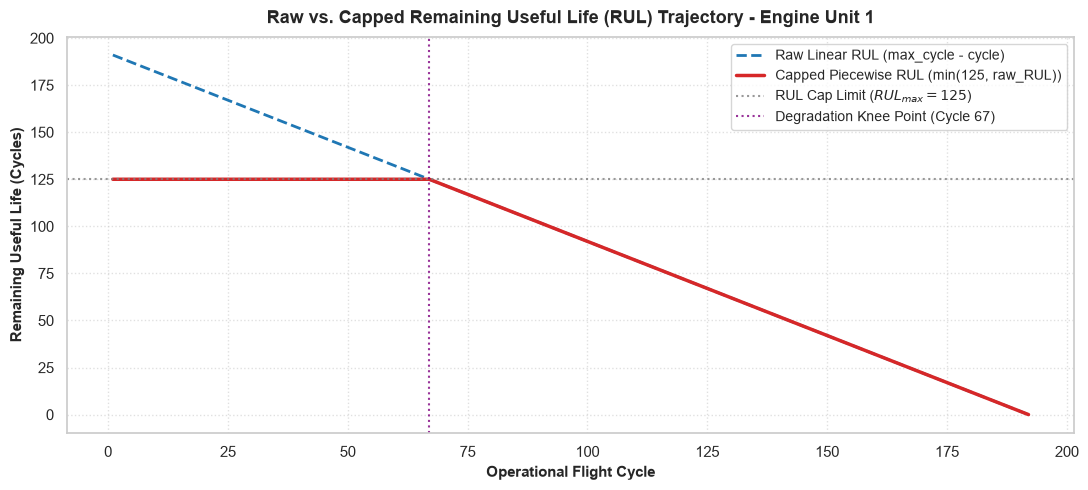

In [5]:
# Plot raw vs. capped RUL trajectory for an example engine (Unit 1)
example_unit = 1
unit_data = train_df[train_df["unit"] == example_unit]

plt.figure(figsize=(11, 5))
plt.plot(
    unit_data["cycle"],
    unit_data["raw_RUL"],
    label="Raw Linear RUL (max_cycle - cycle)",
    color="#1f77b4",
    linestyle="--",
    linewidth=2
)
plt.plot(
    unit_data["cycle"],
    unit_data["RUL"],
    label="Capped Piecewise RUL (min(125, raw_RUL))",
    color="#d62728",
    linewidth=2.5
)

# Annotations and threshold lines
plt.axhline(125, color="gray", linestyle=":", alpha=0.8, label="RUL Cap Limit ($RUL_{max} = 125$)")
knee_cycle = unit_data[unit_data["raw_RUL"] == 125]["cycle"].values[0]
plt.axvline(knee_cycle, color="purple", linestyle=":", alpha=0.8, label=f"Degradation Knee Point (Cycle {knee_cycle})")

plt.title(f"Raw vs. Capped Remaining Useful Life (RUL) Trajectory - Engine Unit {example_unit}", fontsize=13, fontweight="bold", pad=10)
plt.xlabel("Operational Flight Cycle", fontsize=11, fontweight="bold")
plt.ylabel("Remaining Useful Life (Cycles)", fontsize=11, fontweight="bold")
plt.legend(frameon=True, fontsize=10, loc="upper right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

### Interpretation: Piecewise Linear Degradation Trajectory
- **Unit 1 Lifespan:** 192 total cycles.
- **Healthy Baseline Regime (Cycles 1–67):** `raw_RUL` decreases linearly from 191 to 125, while capped `RUL` remains constant at 125. Telemetry during this phase shows no observable degradation, so keeping the target constant avoids penalizing models for predicting normal operational health.
- **Active Degradation Regime (Cycles 67–192):** From the knee point at Cycle 67 onward, `RUL` decreases strictly linearly from 125 down to 0 at Cycle 192, directly tracking physical HPC fault progression until failure.

---
## Stage 3: Validate Labels

We perform four mathematical and operational integrity checks:
1. **Non-negativity:** Verify that neither `raw_RUL` nor `RUL` ever drops below zero.
2. **Terminal Condition:** Verify that the final operating cycle for every training engine has `RUL == 0`.
3. **Upper Bound Compliance:** Verify that no capped `RUL` value exceeds 125.
4. **Descriptive Statistics:** Inspect distributional metrics across all 20,631 observations.

In [6]:
print("=" * 65)
print("STAGE 3: RUL TARGET INTEGRITY CHECKS & ASSERTIONS")
print("=" * 65)

# Check 1: Non-negativity
negative_raw = (train_df["raw_RUL"] < 0).sum()
negative_capped = (train_df["RUL"] < 0).sum()
print(f"Check 1 - Negative raw_RUL count        : {negative_raw}")
print(f"Check 1 - Negative capped RUL count     : {negative_capped}")
assert negative_raw == 0, "Validation Error: Negative values found in raw_RUL!"
assert negative_capped == 0, "Validation Error: Negative values found in capped RUL!"
print("  ✓ PASSED: RUL never becomes negative.")

# Check 2: Final cycle condition (RUL == 0 at terminal cycle for all engines)
final_records = train_df.groupby("unit").last()
non_zero_raw_final = (final_records["raw_RUL"] != 0).sum()
non_zero_capped_final = (final_records["RUL"] != 0).sum()
print(f"\nCheck 2 - Non-zero raw_RUL at final cycle: {non_zero_raw_final}")
print(f"Check 2 - Non-zero capped RUL at end    : {non_zero_capped_final}")
assert non_zero_raw_final == 0, "Validation Error: Final cycle raw_RUL != 0!"
assert non_zero_capped_final == 0, "Validation Error: Final cycle capped RUL != 0!"
print("  ✓ PASSED: Each engine's final training cycle has RUL = 0.")

# Check 3: Upper threshold bound (RUL <= 125)
exceed_cap_count = (train_df["RUL"] > 125).sum()
print(f"\nCheck 3 - Capped RUL values > 125       : {exceed_cap_count}")
assert exceed_cap_count == 0, "Validation Error: Capped RUL exceeds 125!"
print("  ✓ PASSED: No capped RUL exceeds 125.")
print("=" * 65)

STAGE 3: RUL TARGET INTEGRITY CHECKS & ASSERTIONS
Check 1 - Negative raw_RUL count        : 0
Check 1 - Negative capped RUL count     : 0
  ✓ PASSED: RUL never becomes negative.

Check 2 - Non-zero raw_RUL at final cycle: 0
Check 2 - Non-zero capped RUL at end    : 0
  ✓ PASSED: Each engine's final training cycle has RUL = 0.

Check 3 - Capped RUL values > 125       : 0
  ✓ PASSED: No capped RUL exceeds 125.


In [7]:
print("=" * 65)
print("DESCRIPTIVE STATISTICS: RAW vs. CAPPED RUL")
print("=" * 65)
display(train_df[["raw_RUL", "RUL"]].describe().round(4))
print("-" * 65)
at_cap = (train_df["RUL"] == 125).sum()
active_deg = (train_df["RUL"] < 125).sum()
total_obs = len(train_df)
print(f"Total training flight cycles  : {total_obs:,}")
print(f"Cycles in healthy state (RUL=125) : {at_cap:,} ({at_cap / total_obs * 100:.2f}%)")
print(f"Cycles in degrading state (RUL<125): {active_deg:,} ({active_deg / total_obs * 100:.2f}%)")
print("=" * 65)

DESCRIPTIVE STATISTICS: RAW vs. CAPPED RUL


,raw_RUL,RUL
count,20631.0000,20631.0000
mean,107.8079,86.8293
std,68.8810,41.6737
min,0.0000,0.0000
25%,51.0000,51.0000
50%,103.0000,103.0000
75%,155.0000,125.0000
max,361.0000,125.0000


-----------------------------------------------------------------
Total training flight cycles  : 20,631
Cycles in healthy state (RUL=125) : 8,131 (39.41%)
Cycles in degrading state (RUL<125): 12,500 (60.59%)


### Summary of Label Validation Findings
- **Mathematical Bounds Confirmed:** $0 \le \text{RUL} \le 125$ holds across all 20,631 training observations without exception.
- **Terminal Health State Confirmed:** All 100 training engines terminate precisely at $\text{RUL} = 0$ on their respective maximum flight cycle.
- **Distributional Properties:**
  - `raw_RUL`: Mean of **107.81 cycles** with a maximum of **361.0 cycles** (Unit 69) and minimum of **0.0 cycles**.
  - Capped `RUL`: Mean of **86.83 cycles** with a standard deviation of **41.67 cycles** and maximum of **125.0 cycles**.
  - Exactly **8,131 cycles (39.41%)** correspond to the initial baseline health state (capped at 125), and **12,500 cycles (60.59%)** represent progressive degradation towards failure.